# Visualize Convection-Diffusion Data
This notebook provides tools to visualize the dataset generated for convection-diffusion problems. Each sample contains:
- **Diffusion Coefficient ($\kappa$)**: Controls how the field spreads.
- **Velocity Field ($v$)**: An incompressible field $(v_x, v_y)$ that transports the field.
- **Source Term ($f$)**: Localized sources (Gaussian blobs) in the domain.

In [1]:
import torch
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import os
import glob

# Set plot style
# plt.rcParams.update({'font.size': 12})

In [26]:
def load_sample(data_path, idx=0):
    """Loads a single sample by index from the data path."""
    files = sorted(glob.glob(os.path.join(data_path, "*.pt")))
    if not files:
        raise FileNotFoundError(f"No samples found in {data_path}")
    
    sample = torch.load(files[idx], map_location='cpu')
    return sample

# Data Configuration
DATA_PATH = 'data_ill/train'
sample_0 = load_sample(DATA_PATH, idx=200)
print(f"Keys in sample: {list(sample_0.keys())}")
print(f"Shape of kappa: {sample_0['kappa'].shape}")
print(f"Shape of v: {sample_0['v'].shape}")
print(f"Shape of f: {sample_0['f'].shape}")

Keys in sample: ['kappa', 'v', 'f']
Shape of kappa: torch.Size([128, 128])
Shape of v: torch.Size([128, 128, 2])
Shape of f: torch.Size([128, 128])


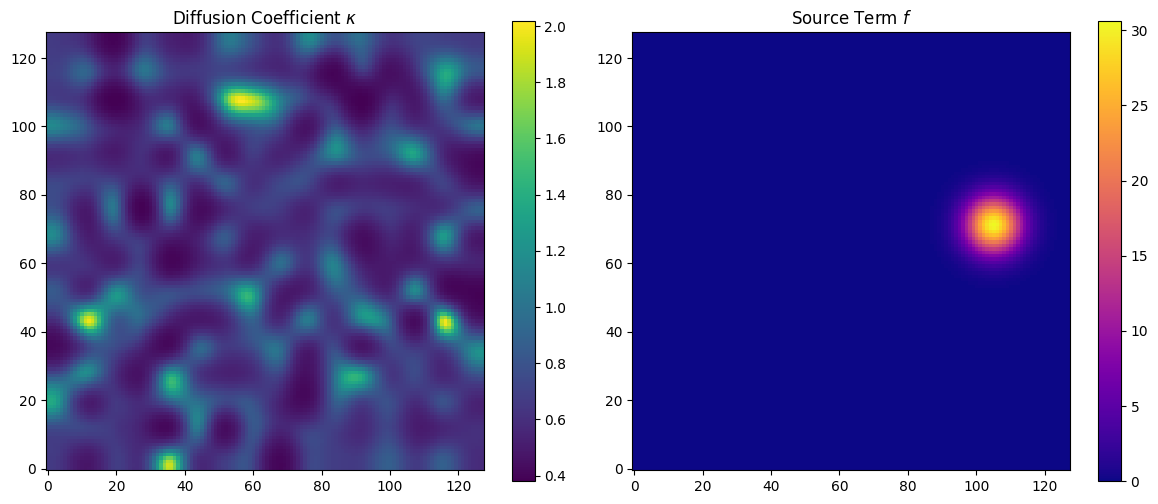

In [27]:
def plot_scalar_fields(sample):
    kappa = sample['kappa'].numpy()
    f = sample['f'].numpy()
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    im1 = axes[0].imshow(kappa, origin='lower', cmap='viridis')
    axes[0].set_title(r'Diffusion Coefficient $\kappa$')
    fig.colorbar(im1, ax=axes[0])
    
    im2 = axes[1].imshow(f, origin='lower', cmap='plasma')
    axes[1].set_title(r'Source Term $f$')
    fig.colorbar(im2, ax=axes[1])
    
    plt.tight_layout()
    plt.show()
sample_0 = load_sample(DATA_PATH, idx=500)
plot_scalar_fields(sample_0)

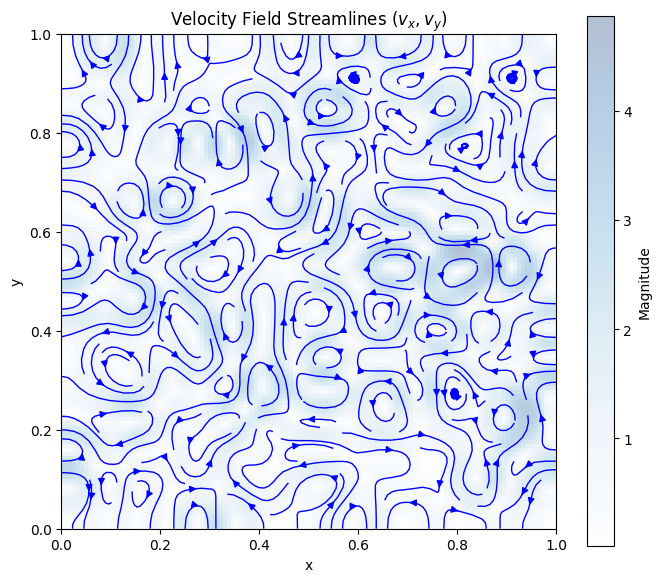

In [28]:
def plot_velocity_field(sample):
    v = sample['v'].numpy()
    vx, vy = v[..., 0], v[..., 1]
    
    H, W = vx.shape
    y, x = np.linspace(0, 1, H), np.linspace(0, 1, W)
    X, Y = np.meshgrid(x, y)
    
    fig, ax = plt.subplots(figsize=(7, 6))
    
    # Plot streamlines
    strm = ax.streamplot(X, Y, vx, vy, color='blue', linewidth=1, density=1.5)
    
    # Plot magnitude as background
    mag = np.sqrt(vx**2 + vy**2)
    im = ax.imshow(mag, origin='lower', extent=[0, 1, 0, 1], cmap='Blues', alpha=0.3)
    
    ax.set_title('Velocity Field Streamlines ($v_x, v_y$)')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    fig.colorbar(im, ax=ax, label='Magnitude')
    
    plt.tight_layout()
    plt.show()

plot_velocity_field(sample_0)

<>:17: SyntaxWarning: invalid escape sequence '\k'
<>:17: SyntaxWarning: invalid escape sequence '\k'
/tmp/ipykernel_13178/4284097740.py:17: SyntaxWarning: invalid escape sequence '\k'
  axes[i, 0].set_title(f'Sample {i*2000}: $\kappa$')


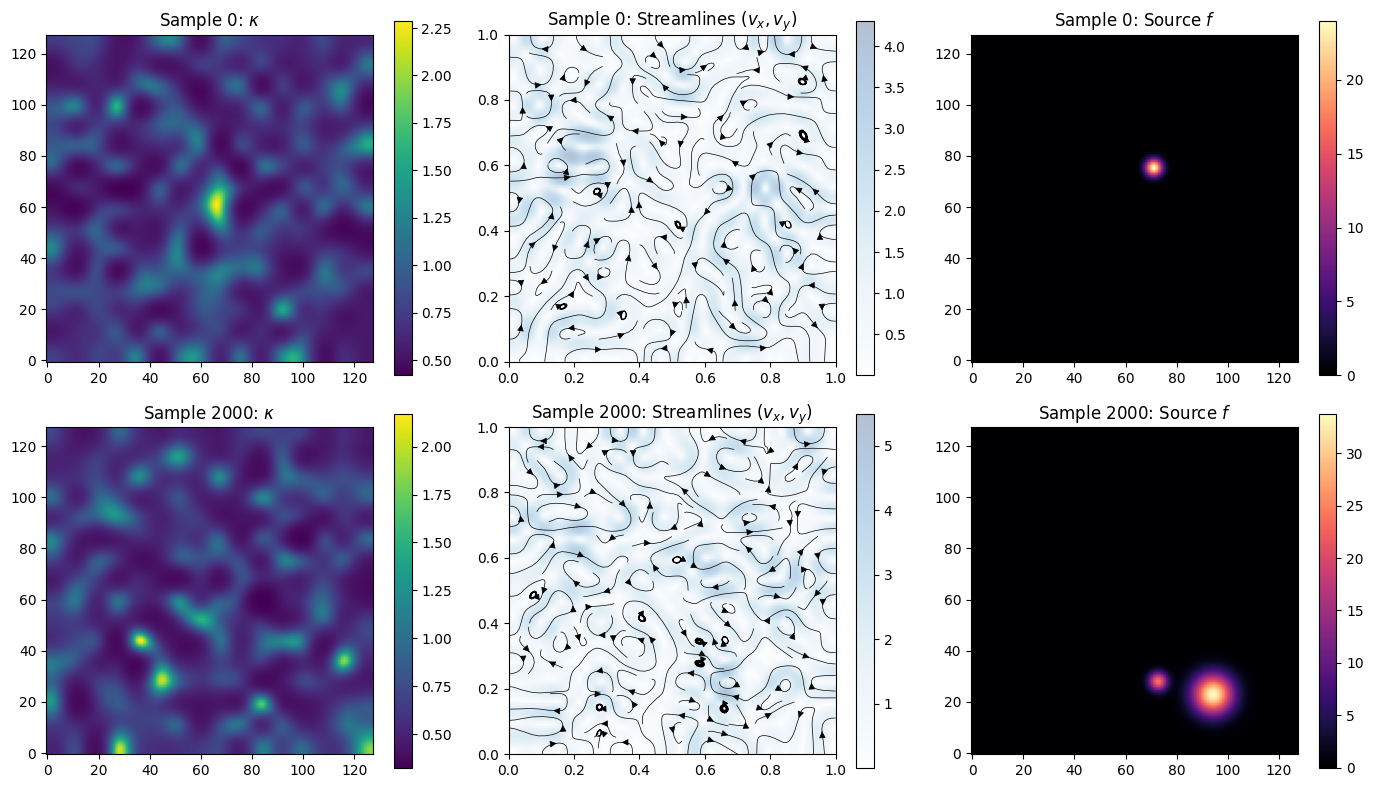

In [29]:
def visualize_multiple_samples(data_path, num_samples=3):
    fig, axes = plt.subplots(num_samples, 3, figsize=(14, 4 * num_samples))
    
    for i in range(num_samples):
        sample = load_sample(data_path, idx=i*2000)
        kappa = sample['kappa'].numpy()
        v = sample['v'].numpy()
        vx, vy = v[..., 0], v[..., 1]
        f = sample['f'].numpy()
        
        H, W = vx.shape
        y, x = np.linspace(0, 1, H), np.linspace(0, 1, W)
        X, Y = np.meshgrid(x, y)
        
        # 1. Kappa
        im0 = axes[i, 0].imshow(kappa, origin='lower', cmap='viridis')
        axes[i, 0].set_title(f'Sample {i*2000}: $\kappa$')
        plt.colorbar(im0, ax=axes[i, 0])
        
        # 2. VX
        # im1 = axes[i, 1].imshow(vx, origin='lower', cmap='RdBu_r')
        # axes[i, 1].set_title(f'Sample {i}: $v_x$')
        # plt.colorbar(im1, ax=axes[i, 1])
        
        # 3. Streamlines
        axes[i, 1].streamplot(X, Y, vx, vy, color='k', linewidth=0.5, density=1)
        axes[i, 1].set_title(f'Sample {i*2000}: Streamlines $(v_x,v_y)$')
        axes[i, 1].set_xlim(0, 1)
        axes[i, 1].set_ylim(0, 1)
        mag = np.sqrt(vx**2 + vy**2)
        im = axes[i, 1].imshow(mag, origin='lower', extent=[0, 1, 0, 1], cmap='Blues', alpha=0.3)
        fig.colorbar(im, ax=axes[i, 1])
        # 4. Source Term
        im3 = axes[i, 2].imshow(f, origin='lower', cmap='magma')
        axes[i, 2].set_title(f'Sample {i*2000}: Source $f$')
        plt.colorbar(im3, ax=axes[i, 2])

    plt.tight_layout()
    plt.show()

visualize_multiple_samples(DATA_PATH, num_samples=2)

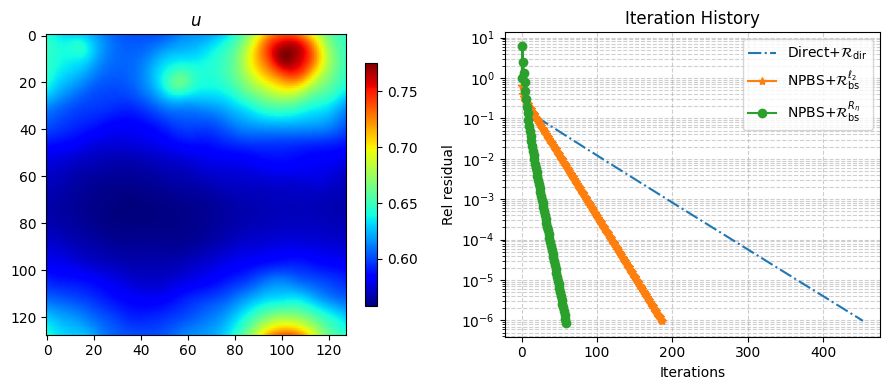

In [5]:
import os
import torch
import matplotlib.pyplot as plt

base_dir = "/afs/L202500118/wangjt/work/precond_loss/cdr"

fno_pre_path = os.path.join(
    base_dir,
    "models/fno_solver_precond_R_eta_04_20_01_53_51/infer_results/sample_2_data.pt",
)
fno_pre_l2_path = os.path.join(
    base_dir,
    "models/fno_solver_precond_L2_04_20_01_53_52/infer_results/sample_2_data.pt",
)
fno_path = os.path.join(
    base_dir,
    "models/fno_solver_L2_04_20_01_53_50/infer_results/sample_2_data.pt",
)
# cbs_path = os.path.join(base_dir, "iter_his_cbs.pt")

fno_pre_data = torch.load(fno_pre_path, weights_only=False)
fno_data = torch.load(fno_path, weights_only=False)
fno_pre_l2_data = torch.load(fno_pre_l2_path, weights_only=False)

u_plot = fno_data["u"][0, 0].cpu().numpy()
loss_fno = fno_data["loss_his"]
loss_fno_pre = fno_pre_data["loss_his"]
loss_fno_pre_l2 = fno_pre_l2_data["loss_his"]
# loss_fno_pre.insert(0,1.)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

im = axes[0].imshow(u_plot, cmap="jet")
axes[0].set_title(r"$u$")
plt.colorbar(im, ax=axes[0], shrink=0.8)

axes[1].plot(loss_fno, '-.',label=r"Direct+$\mathcal{R}_{\mathrm{dir}}$")
axes[1].plot(loss_fno_pre_l2, '-*', label=r"NPBS+$\mathcal{R}_{\mathrm{bs}}^{\ell_2}$")
axes[1].plot(loss_fno_pre, '-o', label=r"NPBS+$\mathcal{R}_{\mathrm{bs}}^{R_\eta}$")

axes[1].set_yscale("log")
axes[1].set_title("Iteration History")
axes[1].set_xlabel("Iterations")
axes[1].set_ylabel("Rel residual")
axes[1].legend()
axes[1].grid(True, which="both", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


In [23]:
loss_fno_pre

[1.0,
 0.09999999403953552,
 0.031945135444402695,
 0.0014917138032615185,
 0.0001659508707234636,
 2.7905403840122744e-05,
 4.52912854598253e-06,
 7.839452109692502e-07]